In [ ]:
import sys
print(sys.executable)

c:\Users\Utkarsh Shukla\AppData\Local\Programs\Python\Python312\python.exe


In [ ]:
# Load the tab-separated dataset
df = pd.read_csv('spam.csv', sep='\t', header=None, names=['label', 'message'])

# Display the first five messages
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
df.info()

Dataset Shape: (5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
label      0
message    0
dtype: int64


In [ ]:
# Count each message category
print(df['label'].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
%pip install numpy pandas matplotlib seaborn scikit-learn

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl (7.3 MB)
U


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


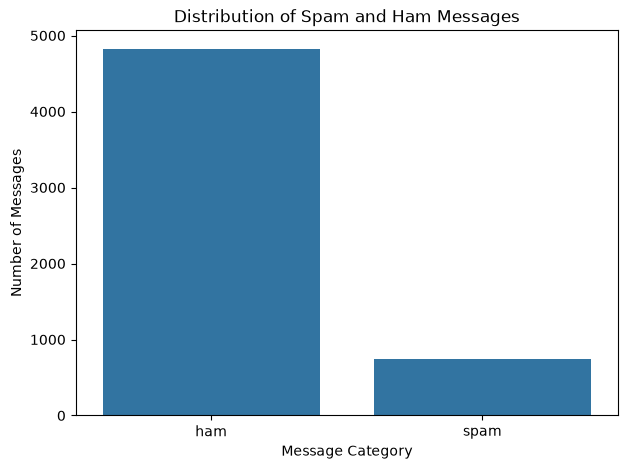

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title('Distribution of Spam and Ham Messages')
plt.xlabel('Message Category')
plt.ylabel('Number of Messages')

plt.show()

In [ ]:
# Remove duplicate messages
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Reset row numbering
df = df.reset_index(drop=True)

# Check the updated dataset
print("Dataset shape after cleaning:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (5169, 2)
Missing values: 0
Duplicate rows: 0


In [ ]:
# Separate input messages and target labels
X = df['message']
y = df['label']

print("Total messages:", len(X))
print("\nMessage categories:")
print(y.value_counts())

Total messages: 5169

Message categories:
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Function to clean SMS messages
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)

    words = text.split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]

    return ' '.join(words)

# Apply preprocessing
df['cleaned_message'] = df['message'].apply(preprocess_text)

# Display original and cleaned messages
df[['message', 'cleaned_message']].head()

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives


In [ ]:
from sklearn.model_selection import train_test_split

# Separate cleaned messages and labels
X = df['cleaned_message']
y = df['label']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Learn vocabulary and transform training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 7282)
Testing data shape: (1034, 7282)


### What is TF-IDF?

TF-IDF stands for **Term Frequency–Inverse Document Frequency**. It is a text feature extraction technique used in Natural Language Processing (NLP).

- **Term Frequency (TF):** Measures how frequently a word appears in a message.
- **Inverse Document Frequency (IDF):** Measures how important a word is by reducing the weight of words that appear frequently across many messages.

TF-IDF gives higher importance to words that help distinguish spam messages from legitimate messages. It converts text into numerical features that machine learning algorithms can understand.

In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict results using both models
nb_predictions = nb_model.predict(X_test_tfidf)
lr_predictions = lr_model.predict(X_test_tfidf)

print("Naive Bayes Predictions:")
print(nb_predictions[:10])

print("\nLogistic Regression Predictions:")
print(lr_predictions[:10])

print("\nActual Labels:")
print(y_test[:10].values)

Naive Bayes Predictions:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']

Logistic Regression Predictions:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']

Actual Labels:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Evaluate Naive Bayes
print("===== MULTINOMIAL NAIVE BAYES =====")
print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

# Evaluate Logistic Regression
print("===== LOGISTIC REGRESSION =====")
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

===== MULTINOMIAL NAIVE BAYES =====
Accuracy: 0.9632495164410058

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.71      0.83       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034

===== LOGISTIC REGRESSION =====
Accuracy: 0.9468085106382979

Classification Report:
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       903
        spam       0.97      0.60      0.74       131

    accuracy                           0.95      1034
   macro avg       0.96      0.80      0.85      1034
weighted avg       0.95      0.95      0.94      1034



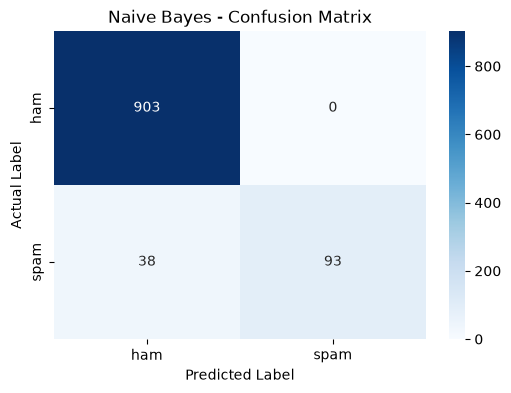

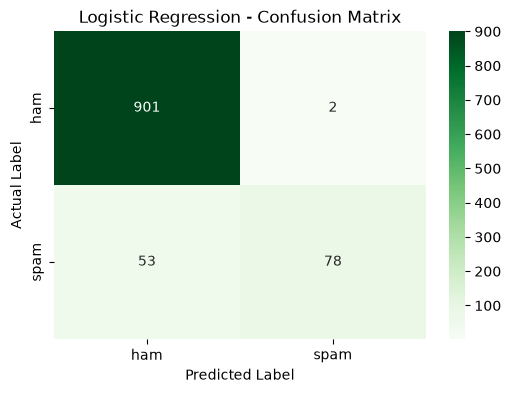

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix for Naive Bayes
nb_cm = confusion_matrix(y_test, nb_predictions, labels=['ham', 'spam'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)
plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# Confusion matrix for Logistic Regression
lr_cm = confusion_matrix(y_test, lr_predictions, labels=['ham', 'spam'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

### Why is Recall Important in Spam Detection?

Recall is an important evaluation metric in spam detection because it measures how many actual spam messages are correctly identified by the model.

A low recall score means that many spam messages are incorrectly classified as legitimate messages (ham). These unwanted messages may reach the user's inbox and could contain phishing links, scams, or harmful content.

A high recall score helps the system detect more spam messages and reduces the chances of missing unwanted messages.

However, precision is also important because incorrectly marking legitimate messages as spam can cause users to miss important emails.

Therefore, a good spam detection system should maintain a suitable balance between recall and precision.